## Проектная работа на тему

## "Обнаружение дефектов бетонных конструкций методами машинного обучения"

Датасет https://www.kaggle.com/datasets/jakubniemiec/concrete-crack-images

In [1]:
import warnings
#warnings.filterwarnings("ignore")

import numpy as np
from torch.utils.data import Dataset, DataLoader
import cv2 as cv
import matplotlib.pyplot as plt
from tqdm import tqdm
import torch
import torch.nn as nn
from tqdm import tqdm
from sklearn.model_selection import train_test_split
import os
import segmentation_models_pytorch as smp
from tqdm import tqdm
import albumentations as A
from albumentations import (Compose, ShiftScaleRotate, Resize, RandomRotate90, ElasticTransform, Rotate,
                            VerticalFlip, HorizontalFlip, RandomBrightnessContrast,  Normalize, ToTensorV2)

import pandas as pd
from glob import glob

import random

In [2]:

def set_seed(seed = 42):
    '''
    Sets the seed of the entire notebook so results are the same every time we run.
    This is for REPRODUCIBILITY.
    '''
    np.random.seed(seed)
    random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)

    # When running on the CuDNN backend, two further options must be set
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    # Set a fixed value for the hash seed
    os.environ['PYTHONHASHSEED'] = str(seed)

set_seed(42)


### Предобработка

In [3]:
img_dir = 'archive/images'
mask_dir = 'archive/masks'

In [4]:
images_paths = glob(img_dir + '/*.jpg')
masks_paths = glob(mask_dir + '/*.png')

images_paths = sorted([str(p) for p in images_paths])
masks_paths = sorted([str(p) for p in masks_paths])

df = pd.DataFrame({'image': images_paths, 'mask': masks_paths})
df

,image,mask
0,archive/images\crack-o-1.jpg,archive/masks\crack-o-1.png
1,archive/images\crack-o-10.jpg,archive/masks\crack-o-10.png
2,archive/images\crack-o-100.jpg,archive/masks\crack-o-100.png
3,archive/images\crack-o-101.jpg,archive/masks\crack-o-101.png
4,archive/images\crack-o-102.jpg,archive/masks\crack-o-102.png
...,...,...
795,archive/images\crack-o-95.jpg,archive/masks\crack-o-95.png
796,archive/images\crack-o-96.jpg,archive/masks\crack-o-96.png
797,archive/images\crack-o-97.jpg,archive/masks\crack-o-97.png
798,archive/images\crack-o-98.jpg,archive/masks\crack-o-98.png


Отметим изображения с трещинами

In [5]:
df['cracked'] = 0
for index, row in df.iterrows():
    mask = cv.imread(row['mask'],cv.IMREAD_GRAYSCALE)
    if mask.max() > 0:
        df.loc[index, 'cracked'] = 1

<Axes: >

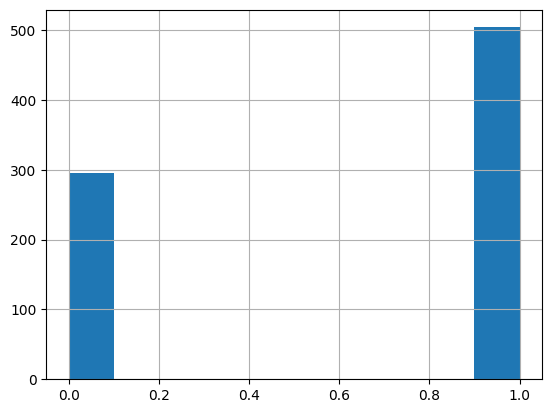

In [6]:
df['cracked'].hist()

In [7]:
df[df['cracked']==1].count()

image      504
mask       504
cracked    504
dtype: int64

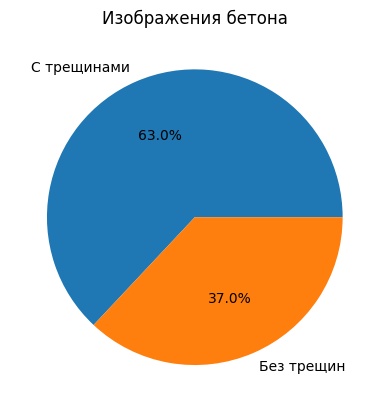

In [8]:
values = [len(df[df['cracked']==1]), len(df[df['cracked']==0])]
labels = ["С трещинами", "Без трещин"]

plt.pie(values, labels=labels, autopct='%1.1f%%' )
plt.title("Изображения бетона")
plt.show()

In [9]:
from sklearn.model_selection import train_test_split

train_df, val_df = train_test_split(df, test_size=0.4, random_state=42, shuffle=True)
val_df, test_df = train_test_split(val_df, test_size=0.5, random_state=42, shuffle=True)

<Axes: >

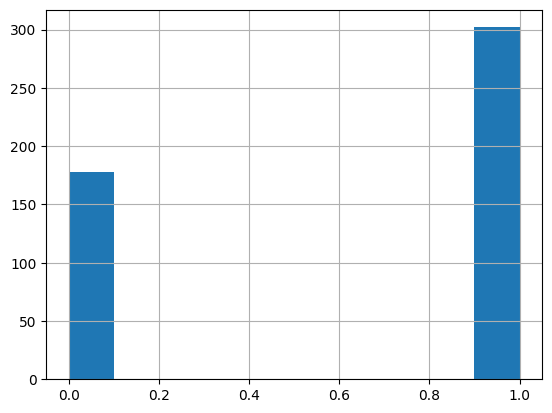

In [10]:
train_df['cracked'].hist()

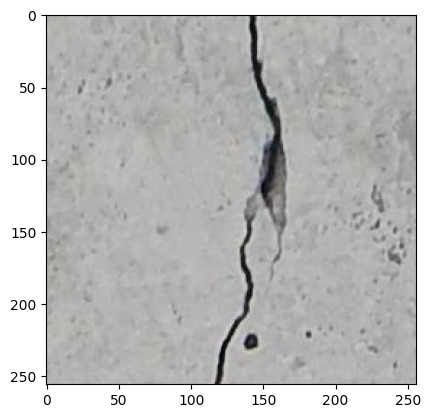

In [11]:
idx = 21
img_path = df[df['cracked']==1]['image'].iloc[idx]
img = image = cv.imread(img_path, cv.IMREAD_COLOR_RGB)
plt.imshow(image)

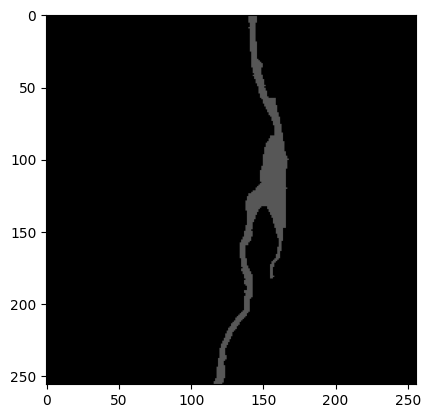

In [12]:
mask_path = df[df['cracked']==1]['mask'].iloc[idx]
mask = cv.imread(mask_path, cv.IMREAD_COLOR_RGB)
plt.imshow(mask)

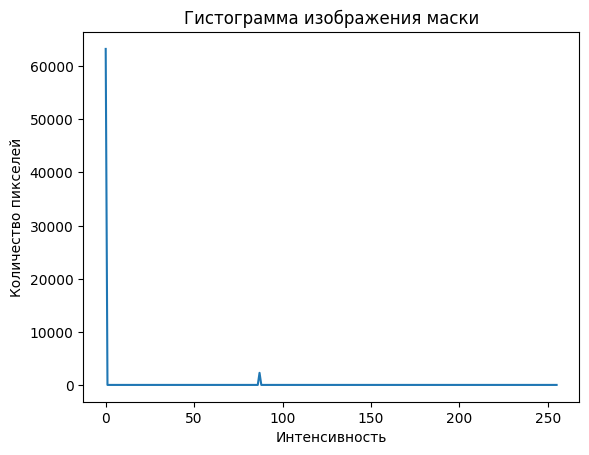

In [13]:
hist = cv.calcHist([mask], [0], None, [256], [0, 256])

plt.plot(hist)
plt.title('Гистограмма изображения маски')
plt.xlabel('Интенсивность')
plt.ylabel('Количество пикселей')
plt.show()

### Датасет

In [14]:
class CrackDataset(Dataset):
    def __init__(self, df, transform=None, mode='train'):
        self.df = df
        self.transform = transform
        self.mode = mode  # 'train', 'val'

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        # Get image ID
        img_path = self.df.iloc[idx]['image']
        # Load image
        image = cv.imread(img_path, cv.IMREAD_COLOR_RGB)


        mask_path = self.df.iloc[idx]['mask']
        mask = cv.imread(mask_path, cv.IMREAD_GRAYSCALE)

        _, mask = cv.threshold(mask, 1, 255, cv.THRESH_BINARY)

        augmented = self.transform(image=image, mask=mask)

        image = augmented['image'].float()/255
        mask = augmented['mask'].unsqueeze(0).float()/255            

        return image, mask

### Аугментация

In [15]:
train_transform = Compose([
    Rotate(limit=45, p=1.0),
    ElasticTransform(alpha=1, sigma=50, p=0.5),
    ShiftScaleRotate(scale_limit=0.5, rotate_limit=0, shift_limit=0.1, p=0.5, border_mode=0),
    RandomRotate90(p=1),
    VerticalFlip(p=0.5),
    HorizontalFlip(p=0.5),
    RandomBrightnessContrast(p=0.5),
    Resize(256, 256),
    Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225), max_pixel_value=255.0),
    ToTensorV2()
])

val_transform = Compose([
    Resize(256, 256),
    Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225), max_pixel_value=255.0),
    ToTensorV2()
])

d:\_Projects\_OTUS_ML\.venv\Lib\site-packages\albumentations\core\validation.py:132: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


### Загрузчики данных

In [16]:
train_dataset = CrackDataset(df=train_df, transform=train_transform)
val_dataset = CrackDataset(df=val_df, transform=val_transform)
test_dataset = CrackDataset(df=test_df, transform=val_transform)

train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=4, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=4, shuffle=False, num_workers=0)

print(len(train_loader))
print(len(val_loader))
print(len(test_loader))

120
40
40


### Модели

#### UNet

In [17]:
class UNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.base = smp.Unet(
            encoder_name="resnet34",      
            encoder_weights="imagenet",     
            in_channels=3,                 
            classes=1                   
            )
    def forward(self, x):
        return self.base(x)

#### UNet++

In [18]:
class UNetPlusPlus(nn.Module):
    def __init__(self):
        super().__init__()
        self.base = smp.UnetPlusPlus(
            encoder_name= "resnet34",   #"efficientnet-b1",
            encoder_weights="imagenet",     
            in_channels=3,                 
            classes=1                   
            )
    def forward(self, x):
        return self.base(x)

#### UNet++ (encoder DenseNet)

In [19]:
class UNetPlusPlusDN(nn.Module):
    def __init__(self):
        super().__init__()
        self.base = smp.UnetPlusPlus(
            encoder_name= "densenet161",
            encoder_depth=5,
            encoder_weights="imagenet",     
            in_channels=3,                 
            classes=1                   
            )
    def forward(self, x):
        return self.base(x)

#### LinkNet

In [20]:
class Linknet(nn.Module):
    def __init__(self):
        super().__init__()
        self.base = smp.Linknet(
            encoder_name= "densenet161",        
            encoder_weights="imagenet",     
            in_channels=3,                 
            classes=1                   
            )
    def forward(self, x):
        return self.base(x)

#### Attention-UNet

In [21]:
class ConvBlock(nn.Module):
    def __init__(self, ch_in, ch_out):
        super().__init__()
        self.conv = nn.Sequential(
                                  nn.Conv2d(ch_in, ch_out,
                                            kernel_size=3, stride=1,
                                            padding=1, bias=True),
                                  nn.BatchNorm2d(ch_out),
                                  nn.ReLU(inplace=True),
                                  nn.Conv2d(ch_out, ch_out,
                                            kernel_size=3, stride=1,
                                            padding=1, bias=True),
                                  nn.BatchNorm2d(ch_out),
                                  nn.ReLU(inplace=True),
        )
        
    def forward(self, x):
        x = self.conv(x)
        return x

In [22]:
class UpConvBlock(nn.Module):
    def __init__(self, ch_in, ch_out):
        super().__init__()
        self.up = nn.Sequential(
                                nn.Upsample(scale_factor=2),
                                nn.Conv2d(ch_in, ch_out,
                                         kernel_size=3,stride=1,
                                         padding=1, bias=True),
                                nn.BatchNorm2d(ch_out),
                                nn.ReLU(inplace=True),
        )
        
    def forward(self, x):
        x = x = self.up(x)
        return x

In [23]:
class AttentionBlock(nn.Module):
    def __init__(self, f_g, f_l, f_int):
        super().__init__()
        
        self.w_g = nn.Sequential(
                                nn.Conv2d(f_g, f_int,
                                         kernel_size=1, stride=1,
                                         padding=0, bias=True),
                                nn.BatchNorm2d(f_int)
        )
        
        self.w_x = nn.Sequential(
                                nn.Conv2d(f_l, f_int,
                                         kernel_size=1, stride=1,
                                         padding=0, bias=True),
                                nn.BatchNorm2d(f_int)
        )
        
        self.psi = nn.Sequential(
                                nn.Conv2d(f_int, 1,
                                         kernel_size=1, stride=1,
                                         padding=0,  bias=True),
                                nn.BatchNorm2d(1),
                                nn.Sigmoid(),
        )
        
        self.relu = nn.ReLU(inplace=True)
        
    def forward(self, g, x):
        g1 = self.w_g(g)
        x1 = self.w_x(x)
        psi = self.relu(g1+x1)
        psi = self.psi(psi)
        
        return psi*x

In [24]:
class AttentionUNet(nn.Module):
    def __init__(self, n_classes=1, in_channel=3, out_channel=1):
        super().__init__() 
        
        self.maxpool = nn.MaxPool2d(kernel_size=2, stride=2)
        
        self.conv1 = ConvBlock(ch_in=in_channel, ch_out=64)
        self.conv2 = ConvBlock(ch_in=64, ch_out=128)
        self.conv3 = ConvBlock(ch_in=128, ch_out=256)
        self.conv4 = ConvBlock(ch_in=256, ch_out=512)
        self.conv5 = ConvBlock(ch_in=512, ch_out=1024)
        
        self.up5 = UpConvBlock(ch_in=1024, ch_out=512)
        self.att5 = AttentionBlock(f_g=512, f_l=512, f_int=256)
        self.upconv5 = ConvBlock(ch_in=1024, ch_out=512)
        
        self.up4 = UpConvBlock(ch_in=512, ch_out=256)
        self.att4 = AttentionBlock(f_g=256, f_l=256, f_int=128)
        self.upconv4 = ConvBlock(ch_in=512, ch_out=256)
        
        self.up3 = UpConvBlock(ch_in=256, ch_out=128)
        self.att3 = AttentionBlock(f_g=128, f_l=128, f_int=64)
        self.upconv3 = ConvBlock(ch_in=256, ch_out=128)
        
        self.up2 = UpConvBlock(ch_in=128, ch_out=64)
        self.att2 = AttentionBlock(f_g=64, f_l=64, f_int=32)
        self.upconv2 = ConvBlock(ch_in=128, ch_out=64)
        
        self.conv_1x1 = nn.Conv2d(64, out_channel,
                                  kernel_size=1, stride=1, padding=0)
        
    def forward(self, x):
        # encoder
        x1 = self.conv1(x)
        
        x2 = self.maxpool(x1)
        x2 = self.conv2(x2)
        
        x3 = self.maxpool(x2)
        x3 = self.conv3(x3)
        
        x4 = self.maxpool(x3)
        x4 = self.conv4(x4)
        
        x5 = self.maxpool(x4)
        x5 = self.conv5(x5)
        
        # decoder + concat
        d5 = self.up5(x5)
        x4 = self.att5(g=d5, x=x4)
        d5 = torch.concat((x4, d5), dim=1)
        d5 = self.upconv5(d5)
        
        d4 = self.up4(d5)
        x3 = self.att4(g=d4, x=x3)
        d4 = torch.concat((x3, d4), dim=1)
        d4 = self.upconv4(d4)
        
        d3 = self.up3(d4)
        x2 = self.att3(g=d3, x=x2)
        d3 = torch.concat((x2, d3), dim=1)
        d3 = self.upconv3(d3)
        
        d2 = self.up2(d3)
        x1 = self.att2(g=d2, x=x1)
        d2 = torch.concat((x1, d2), dim=1)
        d2 = self.upconv2(d2)
        
        d1 = self.conv_1x1(d2)
        
        return d1

#### DeepLabV3 - использовалась как baseline на соревнованиях kaggle
https://www.kaggle.com/code/whchb1122/baseline-deeplabv3-crack-segmentation

In [25]:
class DeepLabV3(nn.Module):
    def __init__(self):
        super().__init__()
        self.base = smp.DeepLabV3(
            encoder_name="resnet101",        
            encoder_weights="imagenet",     
            in_channels=3,                 
            classes=1                   
            )
    def forward(self, x):
        return self.base(x)

#### DeepLabV3+

In [26]:
class DeepLabV3Plus(nn.Module):
    def __init__(self):
        super().__init__()
        self.base = smp.DeepLabV3Plus(
            encoder_name="resnet101",        
            encoder_weights="imagenet",     
            in_channels=3,                 
            classes=1                   
            )
    def forward(self, x):
        return self.base(x)

#### Segformer

In [27]:
class Segformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.base = smp.Segformer(
            encoder_name="densenet161",        
            encoder_weights="imagenet",     
            in_channels=3,                 
            classes=1                   
            )
    def forward(self, x):
        return self.base(x)

### Функция потерь

In [28]:
# Define Dice Loss
class DiceLoss(nn.Module):
    def __init__(self):
        super(DiceLoss, self).__init__()

    def forward(self, inputs, targets, smooth=1):
        inputs = torch.sigmoid(inputs)  # Apply sigmoid to get probabilities
        inputs = inputs.view(-1)
        targets = targets.view(-1)
        intersection = (inputs * targets).sum()
        dice = (2. * intersection + smooth) / (inputs.sum() + targets.sum() + smooth)
        return 1 - dice

#Define BCE + Dice Loss
class BCEDiceLoss(nn.Module):
    def __init__(self):
        super(BCEDiceLoss, self).__init__()
        self.bce = nn.BCEWithLogitsLoss()
        self.dice = DiceLoss()

    def forward(self, inputs, targets):
        bce_loss = self.bce(inputs, targets)
        dice_loss = self.dice(inputs, targets)
        return bce_loss + dice_loss

In [29]:
class EarlyStopping:
    def __init__(self, patience=1000, verbose=False, delta=0):
        """
        Early stops the training if validation loss doesn't improve after a given patience.
        """
        self.patience = patience
        self.verbose = verbose
        self.counter = 0
        self.best_loss = None
        self.early_stop = False
        self.delta = delta  # Minimum change to qualify as an improvement

    def __call__(self, val_loss):
        if self.best_loss is None:
            self.best_loss = val_loss
        elif val_loss > self.best_loss - self.delta:
            self.counter += 1
            if self.verbose:
                print(f'EarlyStopping counter: {self.counter} out of {self.patience}')
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_loss = val_loss
            self.counter = 0

In [30]:
criterion = BCEDiceLoss()

In [31]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [32]:
device

device(type='cuda')

In [33]:
print(f"torch.cuda.is_available(): {torch.cuda.is_available()}")
print(f"torch.version.cuda: {torch.version.cuda}")

torch.cuda.is_available(): True
torch.version.cuda: 13.0


### Метрики

In [34]:
def dice_coef(preds, masks, smooth=1.0):
    masks_f = masks.view(-1)
    preds_f = preds.view(-1)
    intersection = (masks_f * preds_f).sum()
    return (2. * intersection + smooth) / (masks_f.sum() + preds_f.sum() + smooth)

In [35]:
def iou_score(preds, targets, smooth=1.0):
    intersect = (preds * targets).sum(2).sum(1)
    union = (preds + targets).sum(2).sum(1)
    iou = (intersect + smooth) / (union-intersect + smooth)
    iou_metric = ((iou - 0.451)*2*10).floor() / 10
    iou_metric[iou_metric < 0] = 0
    return iou_metric.mean()

In [36]:
def pixel_accuracy(preds, targets):
    preds = (preds > 0.5).float()
    total_train = targets.nelement()
    correct_train = preds.eq(targets.data).sum().item()
    train_accuracy = correct_train / total_train
    return train_accuracy

In [37]:
def precision(preds, targets):
    preds = (preds > 0.5).float()
    
    true_positives = (preds * targets).sum()
    predicted_positives = preds.sum()

    if predicted_positives == 0:
        return 0.0
        
    return true_positives / predicted_positives

In [38]:
def recall(preds, targets):
    preds = (preds > 0.5).float()

    true_positives = (preds * targets).sum()
    
    false_negatives = ((1 - preds) * targets).sum()

    if true_positives == 0:
        recall = 0
    else:
        recall = true_positives / (true_positives + false_negatives)
    return recall

### Обучение моделей

In [39]:
def validate(model, epoch):
    model.eval()
    stream = tqdm(val_loader)
    ldr_len = len(val_loader)
    with torch.no_grad():
        running_loss = 0.0
        dice = 0.0
        iou = 0.0
        acc = 0.0
        prec = 0.0
        rec = 0.0
        for images, masks in stream:
            images, masks = images.to(device), masks.to(device)
            outputs = model(images)
            loss = criterion(outputs, masks)
            running_loss += loss.item()
            preds = torch.sigmoid(outputs)
            dice += dice_coef(preds, masks)
            iou += iou_score(preds, masks)
            acc += pixel_accuracy(preds, masks)
            prec += precision(preds, masks)
            rec += recall(preds, masks)

            stream.set_description(f"Epoch: {epoch}. Validation. Loss: {running_loss/ldr_len:.4f} | Dice: {dice/ldr_len:.4f} | IoU: {iou/ldr_len:.4f} "\
                                   f"| Accuracy: {acc/ldr_len:.6f} | Precision: {prec/ldr_len:.6f} | Recall: {rec/ldr_len:.6f}")

    return running_loss/len(val_loader) , dice/len(val_loader)

In [40]:
def test(model):
    model.eval()
    stream = tqdm(test_loader)
    ldr_len = len(test_loader)
    with torch.no_grad():
        running_loss = 0.0
        dice = 0.0
        iou = 0.0
        acc = 0.0
        prec = 0.0
        rec = 0.0
        for images, masks in stream:
            images, masks = images.to(device), masks.to(device)
            outputs = model(images)
            loss = criterion(outputs, masks)
            running_loss += loss.item()
            preds = torch.sigmoid(outputs)
            dice += dice_coef(preds, masks)
            iou += iou_score(preds, masks)
            acc += pixel_accuracy(preds, masks)
            prec += precision(preds, masks)
            rec += recall(preds, masks)

            stream.set_description(f"Loss: {running_loss/ldr_len:.4f} | Dice: {dice/ldr_len:.4f} | IoU: {iou/ldr_len:.4f} "\
                                   f"| Accuracy: {acc/ldr_len:.6f} | Precision: {prec/ldr_len:.6f} | Recall: {rec/ldr_len:.6f}")

    return 

In [41]:
def train_model(model, optimizer, early_stopping, scheduler,  n_epochs=1000, model_name='model'): 
    best_model = model
    train_history = []
    val_history = []
    best_loss = 1.0
    model.train()
    for epoch in range(n_epochs):
        running_loss = 0.0
        dice = 0.0
        iou = 0.0
        acc = 0.0
        prec = 0.0
        rec = 0.0
        stream = tqdm(train_loader)
        ldr_len = len(train_loader)
        for images, masks in stream:
            images, masks = images.to(device), masks.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, masks)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
            preds = torch.sigmoid(outputs)
            dice += dice_coef(preds, masks)
            iou += iou_score(preds, masks)
            acc += pixel_accuracy(preds, masks)
            prec += precision(preds, masks)
            rec += recall(preds, masks)

            stream.set_description(f"Epoch: {epoch}. Train.      Loss: {running_loss/ldr_len:.4f} | Dice: {dice/ldr_len:.4f} | IoU: {iou/ldr_len:.4f} "\
                                   f"| Accuracy: {acc/ldr_len:.6f} | Precision: {prec/ldr_len:.6f} | Recall: {rec/ldr_len:.6f}")
        
        train_loss = running_loss/len(train_loader)

        val_loss, dice = validate(model, epoch)
        
        scheduler.step(val_loss)

        train_history.append(train_loss)
        val_history.append(val_loss)

        if val_loss < best_loss:
            best_loss = val_loss
            best_model = model
            best_dice = dice
            torch.save(model.state_dict(), model_name+'.pt')
            print('Validation loss decreased. Model saved!')

        epoch+=1

        early_stopping(val_loss)
        if early_stopping.early_stop:
            break
    
    print(f'Best Dice: {best_dice:.4f}')

    return best_model, train_history, val_history



In [42]:
model = UNet().to(device)
early_stopping = EarlyStopping()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)  
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2, min_lr=1e-6)
unet_model, unet_train_history, unet_val_history = train_model(model, optimizer, early_stopping, scheduler, n_epochs=200, model_name='unet_resnet34')

Epoch: 0. Train.      Loss: 1.5207 | Dice: 0.0417 | IoU: 0.0001 | Accuracy: 0.801901 | Precision: 0.105882 | Recall: 0.807505: 100%|██████████| 120/120 [00:11<00:00, 10.32it/s]
Epoch: 0. Validation. Loss: 1.2482 | Dice: 0.0697 | IoU: 0.0004 | Accuracy: 0.987280 | Precision: 0.464758 | Recall: 0.877259: 100%|██████████| 40/40 [00:01<00:00, 38.28it/s]
Epoch: 1. Train.      Loss: 0.6814 | Dice: 0.3755 | IoU: 0.4751 | Accuracy: 0.987585 | Precision: 0.481521 | Recall: 0.522373: 100%|██████████| 120/120 [00:11<00:00, 10.61it/s]
Epoch: 1. Validation. Loss: 0.5443 | Dice: 0.5428 | IoU: 0.7310 | Accuracy: 0.991835 | Precision: 0.756536 | Recall: 0.487332: 100%|██████████| 40/40 [00:01<00:00, 37.95it/s]


Validation loss decreased. Model saved!


Epoch: 2. Train.      Loss: 0.3465 | Dice: 0.6802 | IoU: 0.7164 | Accuracy: 0.993434 | Precision: 0.685449 | Recall: 0.759995: 100%|██████████| 120/120 [00:11<00:00, 10.52it/s]
Epoch: 2. Validation. Loss: 0.2527 | Dice: 0.7642 | IoU: 0.8042 | Accuracy: 0.995015 | Precision: 0.746494 | Recall: 0.813023: 100%|██████████| 40/40 [00:01<00:00, 37.78it/s]


Validation loss decreased. Model saved!


Epoch: 3. Train.      Loss: 0.3081 | Dice: 0.7154 | IoU: 0.7400 | Accuracy: 0.994118 | Precision: 0.710190 | Recall: 0.773919: 100%|██████████| 120/120 [00:12<00:00,  9.85it/s]
Epoch: 3. Validation. Loss: 0.3147 | Dice: 0.7210 | IoU: 0.7852 | Accuracy: 0.994453 | Precision: 0.812728 | Recall: 0.657390: 100%|██████████| 40/40 [00:01<00:00, 38.09it/s]
Epoch: 4. Train.      Loss: 0.2781 | Dice: 0.7560 | IoU: 0.7690 | Accuracy: 0.994638 | Precision: 0.714127 | Recall: 0.769796: 100%|██████████| 120/120 [00:11<00:00, 10.50it/s]
Epoch: 4. Validation. Loss: 0.2312 | Dice: 0.7881 | IoU: 0.8127 | Accuracy: 0.995342 | Precision: 0.826576 | Recall: 0.738040: 100%|██████████| 40/40 [00:01<00:00, 37.99it/s]


Validation loss decreased. Model saved!


... (86 outputs left out)

Epoch: 171. Train.      Loss: 0.1832 | Dice: 0.8324 | IoU: 0.8227 | Accuracy: 0.996342 | Precision: 0.783436 | Recall: 0.832105: 100%|██████████| 120/120 [00:10<00:00, 10.98it/s]
Epoch: 171. Validation. Loss: 0.1626 | Dice: 0.8516 | IoU: 0.8599 | Accuracy: 0.996542 | Precision: 0.818430 | Recall: 0.851845: 100%|██████████| 40/40 [00:01<00:00, 38.49it/s]
Epoch: 172. Train.      Loss: 0.1825 | Dice: 0.8322 | IoU: 0.8292 | Accuracy: 0.996463 | Precision: 0.808366 | Recall: 0.857516: 100%|██████████| 120/120 [00:12<00:00,  9.99it/s]
Epoch: 172. Validation. Loss: 0.1626 | Dice: 0.8516 | IoU: 0.8600 | Accuracy: 0.996548 | Precision: 0.820315 | Recall: 0.849757: 100%|██████████| 40/40 [00:01<00:00, 37.68it/s]
Epoch: 173. Train.      Loss: 0.1762 | Dice: 0.8388 | IoU: 0.8250 | Accuracy: 0.996419 | Precision: 0.757394 | Recall: 0.803923: 100%|██████████| 120/120 [00:11<00:00, 10.33it/s]
Epoch: 173. Validation. Loss: 0.1626 | Dice: 0.8517 | IoU: 0.8602 | Accuracy: 0.996549 | Precision: 0.818947 

Validation loss decreased. Model saved!


Epoch: 175. Train.      Loss: 0.1880 | Dice: 0.8274 | IoU: 0.8211 | Accuracy: 0.996368 | Precision: 0.803558 | Recall: 0.853618: 100%|██████████| 120/120 [00:11<00:00, 10.54it/s]
Epoch: 175. Validation. Loss: 0.1632 | Dice: 0.8511 | IoU: 0.8592 | Accuracy: 0.996520 | Precision: 0.816093 | Recall: 0.853280: 100%|██████████| 40/40 [00:00<00:00, 40.01it/s]
Epoch: 176. Train.      Loss: 0.1907 | Dice: 0.8248 | IoU: 0.8259 | Accuracy: 0.996336 | Precision: 0.800829 | Recall: 0.852197: 100%|██████████| 120/120 [00:11<00:00, 10.77it/s]
Epoch: 176. Validation. Loss: 0.1632 | Dice: 0.8511 | IoU: 0.8593 | Accuracy: 0.996532 | Precision: 0.817945 | Recall: 0.851905: 100%|██████████| 40/40 [00:01<00:00, 38.22it/s]
Epoch: 177. Train.      Loss: 0.1885 | Dice: 0.8263 | IoU: 0.8269 | Accuracy: 0.996471 | Precision: 0.794063 | Recall: 0.844463: 100%|██████████| 120/120 [00:11<00:00, 10.58it/s]
Epoch: 177. Validation. Loss: 0.1632 | Dice: 0.8511 | IoU: 0.8596 | Accuracy: 0.996542 | Precision: 0.821404 

Best Dice: 0.8518


In [43]:
test(unet_model)

Loss: 0.1724 | Dice: 0.8420 | IoU: 0.8582 | Accuracy: 0.996560 | Precision: 0.817721 | Recall: 0.833831: 100%|██████████| 40/40 [00:01<00:00, 37.03it/s]


#### График обучения

In [44]:
def view_train_graphs(title, train, val):
    plt.title(title)
    plt.plot(train, label='train')
    plt.plot(val, label='validation')
    plt.legend()
    plt.xlabel('Epoch')
    plt.ylabel('Loss')   
    plt.show()
    return

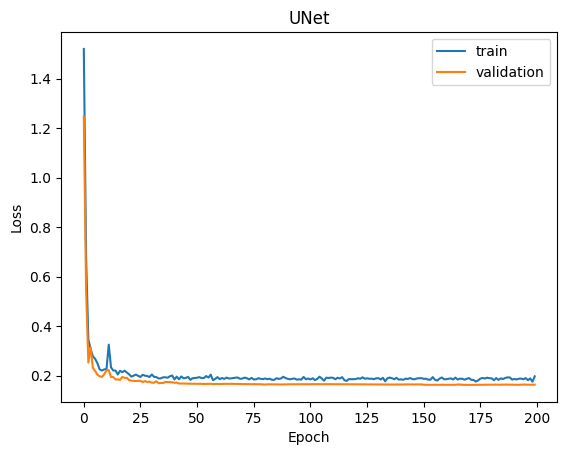

In [45]:
view_train_graphs('UNet',unet_train_history, unet_val_history)

#### Инференс

In [45]:
def view_crack_segmentation(model, idx):
    img_path = df[df['cracked']==1]['image'].iloc[idx]
    img = image = cv.imread(img_path, cv.IMREAD_COLOR_RGB)

    mask_path = df[df['cracked']==1]['mask'].iloc[idx]
    mask = cv.imread(mask_path, cv.IMREAD_COLOR_RGB)

    _, true_mask = cv.threshold(mask, 1, 255, cv.THRESH_BINARY)

    augmented = val_transform(image=image)
    image = augmented['image'].float()/255
    image = image.to(device)
    image = image.unsqueeze(0)
    output = model(image)
    output = output.squeeze()
    probs = torch.sigmoid(output)
    probs = probs.cpu().detach().numpy()
    mask_pred = np.where(probs > 0.5, 255, 0)
    
    fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 12))

    axes[0].set_title('original mask')
    axes[0].axis('off')
    axes[0].imshow(true_mask)    
    axes[1].set_title('predicted mask')
    axes[1].axis('off')
    axes[1].imshow(mask_pred, cmap='gray')
    axes[2].set_title('image with mask')
    axes[2].axis('off')
    axes[2].imshow(img)
    axes[2].imshow(mask_pred, cmap='winter', alpha=mask_pred*0.5/255)

    plt.show()

    return

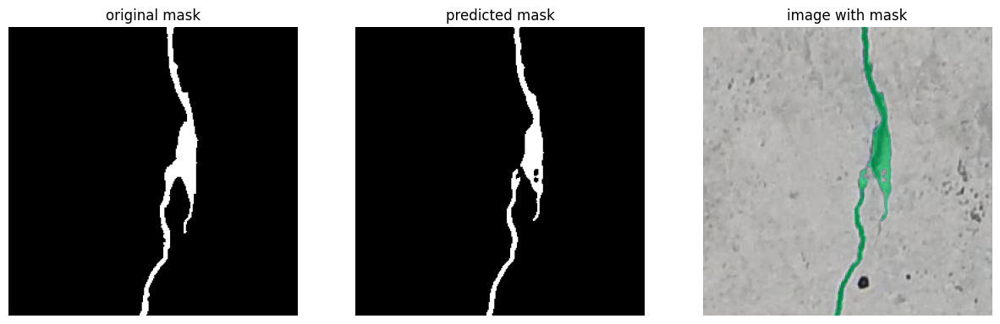

In [47]:
view_crack_segmentation(unet_model, 21)

In [48]:
model = UNetPlusPlus().to(device)
early_stopping = EarlyStopping()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)  
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2, min_lr=1e-6)
unetppr_model, unetppr_train_history, unetppr_val_history = train_model(model, optimizer, early_stopping, scheduler, n_epochs=200, model_name='unetpp_resnet34')

Epoch: 0. Train.      Loss: 1.3149 | Dice: 0.0570 | IoU: 0.0001 | Accuracy: 0.922351 | Precision: 0.238871 | Recall: 0.838861: 100%|██████████| 120/120 [00:13<00:00,  8.78it/s]
Epoch: 0. Validation. Loss: 1.1270 | Dice: 0.0986 | IoU: 0.0008 | Accuracy: 0.986856 | Precision: 0.457037 | Recall: 0.926309: 100%|██████████| 40/40 [00:01<00:00, 32.42it/s]
Epoch: 1. Train.      Loss: 0.4666 | Dice: 0.5754 | IoU: 0.6340 | Accuracy: 0.991793 | Precision: 0.633753 | Recall: 0.677258: 100%|██████████| 120/120 [00:13<00:00,  8.97it/s]
Epoch: 1. Validation. Loss: 0.2560 | Dice: 0.7637 | IoU: 0.8007 | Accuracy: 0.994885 | Precision: 0.741105 | Recall: 0.817177: 100%|██████████| 40/40 [00:01<00:00, 31.96it/s]


Validation loss decreased. Model saved!


Epoch: 2. Train.      Loss: 0.2898 | Dice: 0.7367 | IoU: 0.7557 | Accuracy: 0.994440 | Precision: 0.742771 | Recall: 0.784180: 100%|██████████| 120/120 [00:13<00:00,  8.98it/s]
Epoch: 2. Validation. Loss: 0.2455 | Dice: 0.7747 | IoU: 0.8069 | Accuracy: 0.994925 | Precision: 0.720204 | Recall: 0.865350: 100%|██████████| 40/40 [00:01<00:00, 32.39it/s]


Validation loss decreased. Model saved!


Epoch: 3. Train.      Loss: 0.2731 | Dice: 0.7532 | IoU: 0.7804 | Accuracy: 0.994788 | Precision: 0.744423 | Recall: 0.801154: 100%|██████████| 120/120 [00:13<00:00,  9.08it/s]
Epoch: 3. Validation. Loss: 0.2310 | Dice: 0.7889 | IoU: 0.8230 | Accuracy: 0.995494 | Precision: 0.769200 | Recall: 0.824758: 100%|██████████| 40/40 [00:01<00:00, 32.44it/s]


Validation loss decreased. Model saved!


... (76 outputs left out)

Epoch: 161. Train.      Loss: 0.1850 | Dice: 0.8306 | IoU: 0.8300 | Accuracy: 0.996468 | Precision: 0.803200 | Recall: 0.840430: 100%|██████████| 120/120 [00:12<00:00,  9.34it/s]
Epoch: 161. Validation. Loss: 0.1638 | Dice: 0.8524 | IoU: 0.8622 | Accuracy: 0.996499 | Precision: 0.819146 | Recall: 0.851923: 100%|██████████| 40/40 [00:01<00:00, 33.31it/s]
Epoch: 162. Train.      Loss: 0.1859 | Dice: 0.8297 | IoU: 0.8237 | Accuracy: 0.996426 | Precision: 0.802558 | Recall: 0.839935: 100%|██████████| 120/120 [00:12<00:00,  9.43it/s]
Epoch: 162. Validation. Loss: 0.1638 | Dice: 0.8524 | IoU: 0.8619 | Accuracy: 0.996489 | Precision: 0.817551 | Recall: 0.853317: 100%|██████████| 40/40 [00:01<00:00, 33.24it/s]
Epoch: 163. Train.      Loss: 0.1855 | Dice: 0.8297 | IoU: 0.8277 | Accuracy: 0.996507 | Precision: 0.804326 | Recall: 0.855863: 100%|██████████| 120/120 [00:13<00:00,  9.15it/s]
Epoch: 163. Validation. Loss: 0.1635 | Dice: 0.8526 | IoU: 0.8626 | Accuracy: 0.996530 | Precision: 0.823486 

Validation loss decreased. Model saved!


Epoch: 165. Train.      Loss: 0.1766 | Dice: 0.8385 | IoU: 0.8250 | Accuracy: 0.996491 | Precision: 0.808570 | Recall: 0.849977: 100%|██████████| 120/120 [00:12<00:00,  9.33it/s]
Epoch: 165. Validation. Loss: 0.1638 | Dice: 0.8525 | IoU: 0.8623 | Accuracy: 0.996508 | Precision: 0.819924 | Recall: 0.851502: 100%|██████████| 40/40 [00:01<00:00, 32.89it/s]
Epoch: 166. Train.      Loss: 0.1814 | Dice: 0.8332 | IoU: 0.8387 | Accuracy: 0.996622 | Precision: 0.793826 | Recall: 0.837870: 100%|██████████| 120/120 [00:13<00:00,  9.23it/s]
Epoch: 166. Validation. Loss: 0.1639 | Dice: 0.8524 | IoU: 0.8623 | Accuracy: 0.996507 | Precision: 0.820190 | Recall: 0.851159: 100%|██████████| 40/40 [00:01<00:00, 32.73it/s]
Epoch: 167. Train.      Loss: 0.1832 | Dice: 0.8312 | IoU: 0.8361 | Accuracy: 0.996650 | Precision: 0.809990 | Recall: 0.851314: 100%|██████████| 120/120 [00:13<00:00,  8.97it/s]
Epoch: 167. Validation. Loss: 0.1642 | Dice: 0.8521 | IoU: 0.8617 | Accuracy: 0.996477 | Precision: 0.816845 

Best Dice: 0.8527


In [55]:
test(unetppr_model)

Loss: 0.1655 | Dice: 0.8485 | IoU: 0.8642 | Accuracy: 0.996699 | Precision: 0.821475 | Recall: 0.839752: 100%|██████████| 40/40 [00:01<00:00, 26.06it/s]


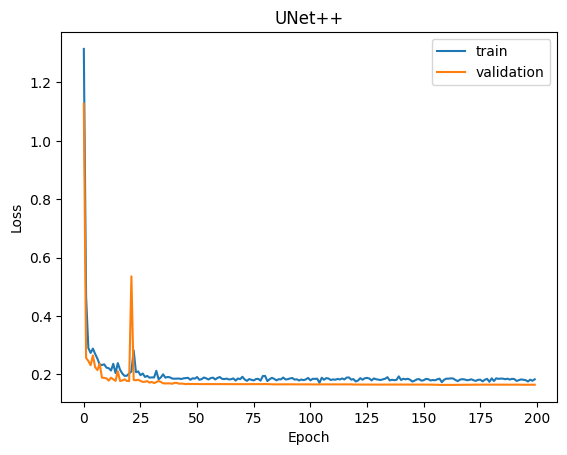

In [49]:
view_train_graphs('UNet++',unetppr_train_history, unetppr_val_history)

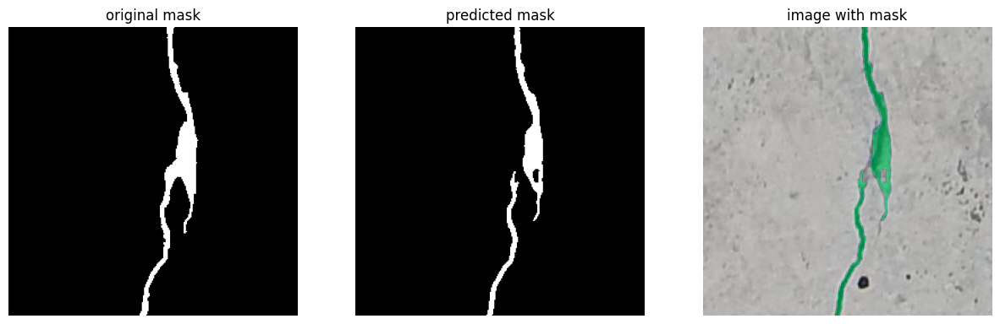

In [50]:
view_crack_segmentation(unetppr_model, 21)

In [51]:
model = UNetPlusPlusDN().to(device)
early_stopping = EarlyStopping()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)  
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2, min_lr=1e-6)
unetpp_model, unetpp_train_history, unetpp_val_history = train_model(model, optimizer, early_stopping, scheduler, n_epochs=200, model_name='unetpp_densenet161')

Epoch: 0. Train.      Loss: 1.3137 | Dice: 0.0638 | IoU: 0.0001 | Accuracy: 0.957695 | Precision: 0.381709 | Recall: 0.912644: 100%|██████████| 120/120 [00:37<00:00,  3.22it/s]
Epoch: 0. Validation. Loss: 1.1665 | Dice: 0.0929 | IoU: 0.0010 | Accuracy: 0.989855 | Precision: 0.521885 | Recall: 0.942604: 100%|██████████| 40/40 [00:03<00:00, 10.11it/s]
Epoch: 1. Train.      Loss: 0.4459 | Dice: 0.6107 | IoU: 0.6525 | Accuracy: 0.990533 | Precision: 0.660846 | Recall: 0.733529: 100%|██████████| 120/120 [00:35<00:00,  3.39it/s]
Epoch: 1. Validation. Loss: 0.2410 | Dice: 0.7791 | IoU: 0.8127 | Accuracy: 0.995027 | Precision: 0.734204 | Recall: 0.843717: 100%|██████████| 40/40 [00:03<00:00, 10.12it/s]


Validation loss decreased. Model saved!


Epoch: 2. Train.      Loss: 0.2500 | Dice: 0.7746 | IoU: 0.7819 | Accuracy: 0.994993 | Precision: 0.763405 | Recall: 0.814264: 100%|██████████| 120/120 [00:34<00:00,  3.44it/s]
Epoch: 2. Validation. Loss: 0.2380 | Dice: 0.7802 | IoU: 0.8139 | Accuracy: 0.995086 | Precision: 0.786341 | Recall: 0.784812: 100%|██████████| 40/40 [00:03<00:00, 10.29it/s]


Validation loss decreased. Model saved!


Epoch: 3. Train.      Loss: 0.2345 | Dice: 0.7875 | IoU: 0.7927 | Accuracy: 0.995625 | Precision: 0.756629 | Recall: 0.816551: 100%|██████████| 120/120 [00:34<00:00,  3.50it/s]
Epoch: 3. Validation. Loss: 0.2881 | Dice: 0.7522 | IoU: 0.8156 | Accuracy: 0.994922 | Precision: 0.860790 | Recall: 0.652536: 100%|██████████| 40/40 [00:03<00:00, 10.30it/s]
Epoch: 4. Train.      Loss: 0.2339 | Dice: 0.7859 | IoU: 0.8023 | Accuracy: 0.995595 | Precision: 0.750671 | Recall: 0.801050: 100%|██████████| 120/120 [00:34<00:00,  3.52it/s]
Epoch: 4. Validation. Loss: 0.1893 | Dice: 0.8283 | IoU: 0.8429 | Accuracy: 0.996025 | Precision: 0.809325 | Recall: 0.818408: 100%|██████████| 40/40 [00:03<00:00, 10.43it/s]


Validation loss decreased. Model saved!


... (98 outputs left out)

Epoch: 180. Train.      Loss: 0.1772 | Dice: 0.8374 | IoU: 0.8312 | Accuracy: 0.996591 | Precision: 0.786612 | Recall: 0.837645: 100%|██████████| 120/120 [00:34<00:00,  3.46it/s]
Epoch: 180. Validation. Loss: 0.1635 | Dice: 0.8512 | IoU: 0.8607 | Accuracy: 0.996481 | Precision: 0.812515 | Recall: 0.855689: 100%|██████████| 40/40 [00:03<00:00, 10.33it/s]
Epoch: 181. Train.      Loss: 0.1821 | Dice: 0.8326 | IoU: 0.8393 | Accuracy: 0.996533 | Precision: 0.793741 | Recall: 0.839047: 100%|██████████| 120/120 [00:34<00:00,  3.46it/s]
Epoch: 181. Validation. Loss: 0.1637 | Dice: 0.8511 | IoU: 0.8604 | Accuracy: 0.996462 | Precision: 0.809234 | Recall: 0.859297: 100%|██████████| 40/40 [00:03<00:00, 10.21it/s]
Epoch: 182. Train.      Loss: 0.1845 | Dice: 0.8304 | IoU: 0.8297 | Accuracy: 0.996491 | Precision: 0.787519 | Recall: 0.839769: 100%|██████████| 120/120 [00:34<00:00,  3.48it/s]
Epoch: 182. Validation. Loss: 0.1634 | Dice: 0.8513 | IoU: 0.8607 | Accuracy: 0.996482 | Precision: 0.811749 

Validation loss decreased. Model saved!


Epoch: 188. Train.      Loss: 0.1842 | Dice: 0.8307 | IoU: 0.8316 | Accuracy: 0.996518 | Precision: 0.809429 | Recall: 0.852326: 100%|██████████| 120/120 [00:34<00:00,  3.43it/s]
Epoch: 188. Validation. Loss: 0.1633 | Dice: 0.8514 | IoU: 0.8608 | Accuracy: 0.996496 | Precision: 0.811898 | Recall: 0.857424: 100%|██████████| 40/40 [00:03<00:00, 10.16it/s]
Epoch: 189. Train.      Loss: 0.1780 | Dice: 0.8367 | IoU: 0.8273 | Accuracy: 0.996543 | Precision: 0.796970 | Recall: 0.842311: 100%|██████████| 120/120 [00:35<00:00,  3.42it/s]
Epoch: 189. Validation. Loss: 0.1633 | Dice: 0.8514 | IoU: 0.8610 | Accuracy: 0.996499 | Precision: 0.812797 | Recall: 0.856634: 100%|██████████| 40/40 [00:03<00:00, 10.11it/s]
Epoch: 190. Train.      Loss: 0.1822 | Dice: 0.8319 | IoU: 0.8304 | Accuracy: 0.996640 | Precision: 0.801684 | Recall: 0.845214: 100%|██████████| 120/120 [00:35<00:00,  3.42it/s]
Epoch: 190. Validation. Loss: 0.1634 | Dice: 0.8513 | IoU: 0.8606 | Accuracy: 0.996477 | Precision: 0.809304 

Best Dice: 0.8515


In [54]:
test(unetpp_model)

Loss: 0.1652 | Dice: 0.8488 | IoU: 0.8664 | Accuracy: 0.996666 | Precision: 0.818714 | Recall: 0.843958: 100%|██████████| 40/40 [00:04<00:00,  9.02it/s]


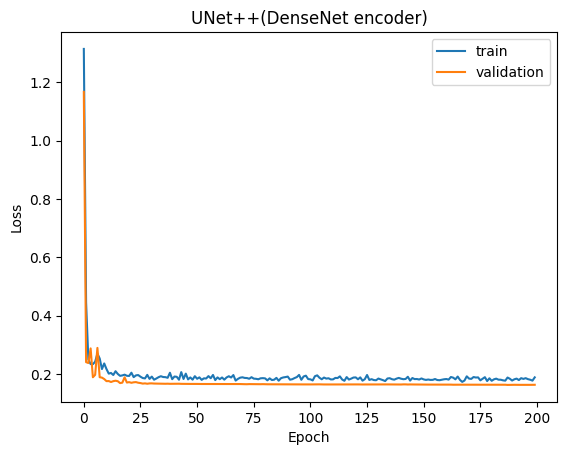

In [52]:
view_train_graphs('UNet++(DenseNet encoder)',unetpp_train_history, unetpp_val_history)

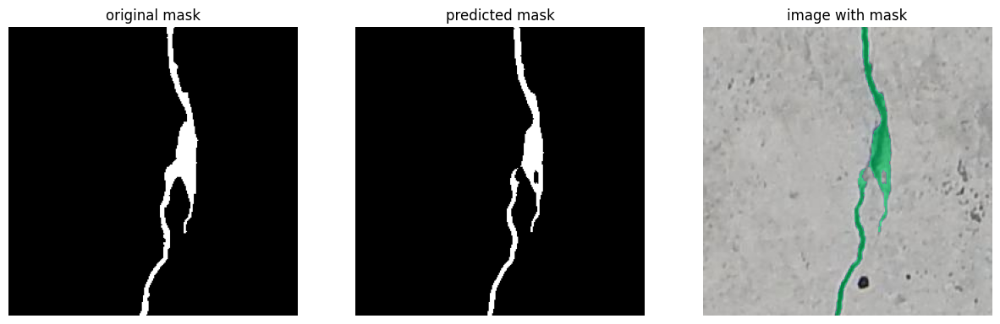

In [56]:
view_crack_segmentation(unetpp_model, 21)

In [46]:
model = Linknet().to(device)
early_stopping = EarlyStopping()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)  
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2, min_lr=1e-6)
linknet_model, linknet_train_history, linknet_val_history = train_model(model, optimizer, early_stopping, scheduler, n_epochs=200, model_name='linknet')

Epoch: 0. Train.      Loss: 1.4773 | Dice: 0.0329 | IoU: 0.0000 | Accuracy: 0.890736 | Precision: 0.089828 | Recall: 0.426194: 100%|██████████| 120/120 [00:23<00:00,  5.05it/s]
Epoch: 0. Validation. Loss: 1.3200 | Dice: 0.0472 | IoU: 0.0001 | Accuracy: 0.965764 | Precision: 0.156356 | Recall: 0.396807: 100%|██████████| 40/40 [00:02<00:00, 19.95it/s]
Epoch: 1. Train.      Loss: 0.8602 | Dice: 0.2235 | IoU: 0.2524 | Accuracy: 0.987741 | Precision: 0.307008 | Recall: 0.252398: 100%|██████████| 120/120 [00:21<00:00,  5.66it/s]
Epoch: 1. Validation. Loss: 0.3873 | Dice: 0.6458 | IoU: 0.7251 | Accuracy: 0.991936 | Precision: 0.632463 | Recall: 0.756351: 100%|██████████| 40/40 [00:02<00:00, 19.57it/s]


Validation loss decreased. Model saved!


Epoch: 2. Train.      Loss: 0.3423 | Dice: 0.6844 | IoU: 0.7337 | Accuracy: 0.993518 | Precision: 0.674421 | Recall: 0.752569: 100%|██████████| 120/120 [00:21<00:00,  5.69it/s]
Epoch: 2. Validation. Loss: 0.2390 | Dice: 0.7801 | IoU: 0.8096 | Accuracy: 0.995140 | Precision: 0.746459 | Recall: 0.828528: 100%|██████████| 40/40 [00:02<00:00, 19.41it/s]


Validation loss decreased. Model saved!


Epoch: 3. Train.      Loss: 0.2755 | Dice: 0.7487 | IoU: 0.7689 | Accuracy: 0.994637 | Precision: 0.737077 | Recall: 0.806469: 100%|██████████| 120/120 [00:20<00:00,  5.74it/s]
Epoch: 3. Validation. Loss: 0.2396 | Dice: 0.7810 | IoU: 0.8022 | Accuracy: 0.994474 | Precision: 0.684097 | Recall: 0.890938: 100%|██████████| 40/40 [00:02<00:00, 19.63it/s]
Epoch: 4. Train.      Loss: 0.3166 | Dice: 0.7135 | IoU: 0.7686 | Accuracy: 0.994435 | Precision: 0.725502 | Recall: 0.748626: 100%|██████████| 120/120 [00:20<00:00,  5.86it/s]
Epoch: 4. Validation. Loss: 0.2872 | Dice: 0.7367 | IoU: 0.7710 | Accuracy: 0.993851 | Precision: 0.666366 | Recall: 0.858027: 100%|██████████| 40/40 [00:02<00:00, 19.15it/s]
Epoch: 5. Train.      Loss: 0.2489 | Dice: 0.7714 | IoU: 0.7774 | Accuracy: 0.994916 | Precision: 0.738206 | Recall: 0.810531: 100%|██████████| 120/120 [00:20<00:00,  5.88it/s]
Epoch: 5. Validation. Loss: 0.2053 | Dice: 0.8164 | IoU: 0.8372 | Accuracy: 0.995616 | Precision: 0.773965 | Recall: 0.

Validation loss decreased. Model saved!


... (74 outputs left out)

Epoch: 178. Train.      Loss: 0.1854 | Dice: 0.8300 | IoU: 0.8231 | Accuracy: 0.996391 | Precision: 0.798045 | Recall: 0.843202: 100%|██████████| 120/120 [00:20<00:00,  5.87it/s]
Epoch: 178. Validation. Loss: 0.1626 | Dice: 0.8521 | IoU: 0.8603 | Accuracy: 0.996470 | Precision: 0.811571 | Recall: 0.856059: 100%|██████████| 40/40 [00:02<00:00, 19.67it/s]


Validation loss decreased. Model saved!


Epoch: 179. Train.      Loss: 0.1886 | Dice: 0.8270 | IoU: 0.8260 | Accuracy: 0.996344 | Precision: 0.800169 | Recall: 0.853375: 100%|██████████| 120/120 [00:20<00:00,  5.84it/s]
Epoch: 179. Validation. Loss: 0.1626 | Dice: 0.8520 | IoU: 0.8605 | Accuracy: 0.996476 | Precision: 0.813624 | Recall: 0.853562: 100%|██████████| 40/40 [00:02<00:00, 19.37it/s]
Epoch: 180. Train.      Loss: 0.1836 | Dice: 0.8316 | IoU: 0.8272 | Accuracy: 0.996427 | Precision: 0.804859 | Recall: 0.856173: 100%|██████████| 120/120 [00:20<00:00,  5.73it/s]
Epoch: 180. Validation. Loss: 0.1631 | Dice: 0.8516 | IoU: 0.8602 | Accuracy: 0.996466 | Precision: 0.813826 | Recall: 0.852667: 100%|██████████| 40/40 [00:02<00:00, 19.81it/s]
Epoch: 181. Train.      Loss: 0.1850 | Dice: 0.8297 | IoU: 0.8321 | Accuracy: 0.996499 | Precision: 0.811660 | Recall: 0.863776: 100%|██████████| 120/120 [00:20<00:00,  5.78it/s]
Epoch: 181. Validation. Loss: 0.1634 | Dice: 0.8514 | IoU: 0.8607 | Accuracy: 0.996467 | Precision: 0.816812 

Best Dice: 0.8521


In [47]:
test(linknet_model)

Loss: 0.1686 | Dice: 0.8455 | IoU: 0.8628 | Accuracy: 0.996597 | Precision: 0.818025 | Recall: 0.836152: 100%|██████████| 40/40 [00:04<00:00,  9.05it/s]


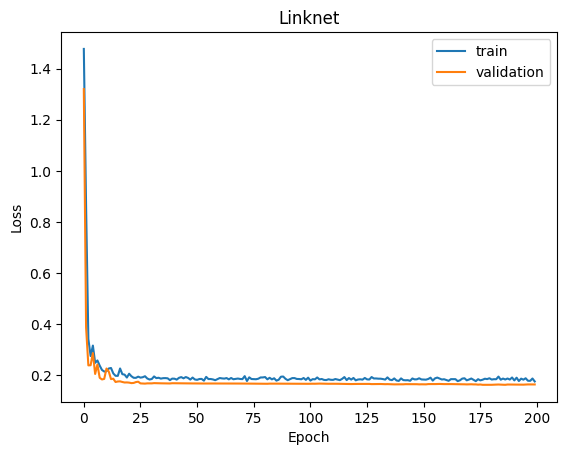

In [48]:
view_train_graphs('Linknet',linknet_train_history, linknet_val_history)

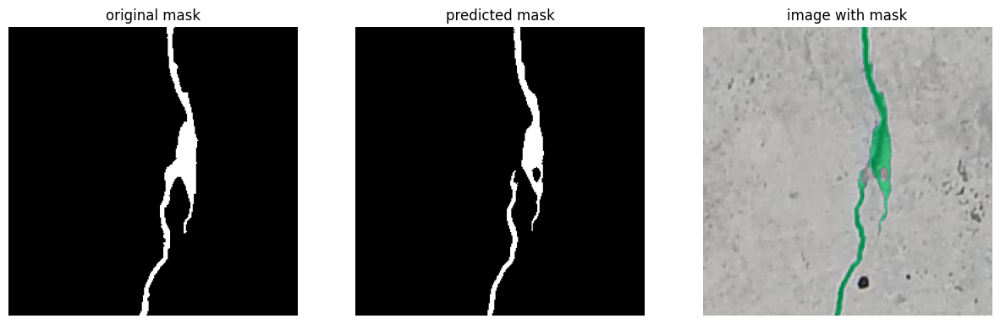

In [49]:
view_crack_segmentation(linknet_model, 21)

In [61]:
model = AttentionUNet().to(device)
early_stopping = EarlyStopping()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)  
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2, min_lr=1e-6)
attentionunet_model, attentionunet_train_history, attentionunet_val_history = train_model(model, optimizer, early_stopping, scheduler, n_epochs=200, model_name='attention_unet')

Epoch: 0. Train.      Loss: 1.2023 | Dice: 0.0657 | IoU: 0.0003 | Accuracy: 0.982609 | Precision: 0.388027 | Recall: 0.669290: 100%|██████████| 120/120 [00:22<00:00,  5.29it/s]
Epoch: 0. Validation. Loss: 1.1169 | Dice: 0.1081 | IoU: 0.0009 | Accuracy: 0.983105 | Precision: 0.432787 | Recall: 0.863943: 100%|██████████| 40/40 [00:02<00:00, 18.62it/s]
Epoch: 1. Train.      Loss: 0.6287 | Dice: 0.4437 | IoU: 0.5606 | Accuracy: 0.986368 | Precision: 0.554395 | Recall: 0.527180: 100%|██████████| 120/120 [00:22<00:00,  5.44it/s]
Epoch: 1. Validation. Loss: 0.4956 | Dice: 0.5627 | IoU: 0.6234 | Accuracy: 0.983967 | Precision: 0.464368 | Recall: 0.820990: 100%|██████████| 40/40 [00:02<00:00, 19.79it/s]


Validation loss decreased. Model saved!


Epoch: 2. Train.      Loss: 0.4666 | Dice: 0.5783 | IoU: 0.6592 | Accuracy: 0.990584 | Precision: 0.616689 | Recall: 0.625015: 100%|██████████| 120/120 [00:21<00:00,  5.54it/s]
Epoch: 2. Validation. Loss: 0.3440 | Dice: 0.6877 | IoU: 0.7598 | Accuracy: 0.993173 | Precision: 0.724373 | Recall: 0.699648: 100%|██████████| 40/40 [00:02<00:00, 19.81it/s]


Validation loss decreased. Model saved!


Epoch: 3. Train.      Loss: 0.4390 | Dice: 0.6027 | IoU: 0.6854 | Accuracy: 0.991668 | Precision: 0.668169 | Recall: 0.632037: 100%|██████████| 120/120 [00:21<00:00,  5.57it/s]
Epoch: 3. Validation. Loss: 0.3949 | Dice: 0.6532 | IoU: 0.6784 | Accuracy: 0.989192 | Precision: 0.554596 | Recall: 0.865033: 100%|██████████| 40/40 [00:02<00:00, 19.80it/s]
Epoch: 4. Train.      Loss: 0.4071 | Dice: 0.6356 | IoU: 0.7196 | Accuracy: 0.992222 | Precision: 0.677079 | Recall: 0.659146: 100%|██████████| 120/120 [00:21<00:00,  5.56it/s]
Epoch: 4. Validation. Loss: 0.3369 | Dice: 0.6968 | IoU: 0.7394 | Accuracy: 0.992176 | Precision: 0.654407 | Recall: 0.797642: 100%|██████████| 40/40 [00:02<00:00, 19.82it/s]


Validation loss decreased. Model saved!


... (88 outputs left out)

Epoch: 194. Train.      Loss: 0.2113 | Dice: 0.8059 | IoU: 0.8175 | Accuracy: 0.996095 | Precision: 0.786513 | Recall: 0.826664: 100%|██████████| 120/120 [00:21<00:00,  5.51it/s]
Epoch: 194. Validation. Loss: 0.1951 | Dice: 0.8244 | IoU: 0.8431 | Accuracy: 0.995793 | Precision: 0.779784 | Recall: 0.839229: 100%|██████████| 40/40 [00:02<00:00, 19.99it/s]
Epoch: 195. Train.      Loss: 0.2158 | Dice: 0.8023 | IoU: 0.8095 | Accuracy: 0.995917 | Precision: 0.787814 | Recall: 0.835638: 100%|██████████| 120/120 [00:21<00:00,  5.48it/s]
Epoch: 195. Validation. Loss: 0.1943 | Dice: 0.8251 | IoU: 0.8435 | Accuracy: 0.995825 | Precision: 0.783363 | Recall: 0.836031: 100%|██████████| 40/40 [00:01<00:00, 20.10it/s]
Epoch: 196. Train.      Loss: 0.2111 | Dice: 0.8073 | IoU: 0.8124 | Accuracy: 0.995985 | Precision: 0.783266 | Recall: 0.810789: 100%|██████████| 120/120 [00:21<00:00,  5.64it/s]
Epoch: 196. Validation. Loss: 0.1947 | Dice: 0.8252 | IoU: 0.8438 | Accuracy: 0.995834 | Precision: 0.785142 

Validation loss decreased. Model saved!


Epoch: 198. Train.      Loss: 0.2075 | Dice: 0.8097 | IoU: 0.8263 | Accuracy: 0.996206 | Precision: 0.798293 | Recall: 0.820210: 100%|██████████| 120/120 [00:21<00:00,  5.67it/s]
Epoch: 198. Validation. Loss: 0.1942 | Dice: 0.8255 | IoU: 0.8438 | Accuracy: 0.995816 | Precision: 0.782630 | Recall: 0.835728: 100%|██████████| 40/40 [00:01<00:00, 20.34it/s]
Epoch: 199. Train.      Loss: 0.2109 | Dice: 0.8060 | IoU: 0.8211 | Accuracy: 0.996187 | Precision: 0.789512 | Recall: 0.843014: 100%|██████████| 120/120 [00:20<00:00,  5.72it/s]
Epoch: 199. Validation. Loss: 0.1940 | Dice: 0.8253 | IoU: 0.8434 | Accuracy: 0.995818 | Precision: 0.782294 | Recall: 0.837123: 100%|██████████| 40/40 [00:02<00:00, 19.95it/s]


Best Dice: 0.8255


In [62]:
test(attentionunet_model)

Loss: 0.2122 | Dice: 0.8047 | IoU: 0.8507 | Accuracy: 0.996178 | Precision: 0.796879 | Recall: 0.827655: 100%|██████████| 40/40 [00:02<00:00, 15.89it/s]


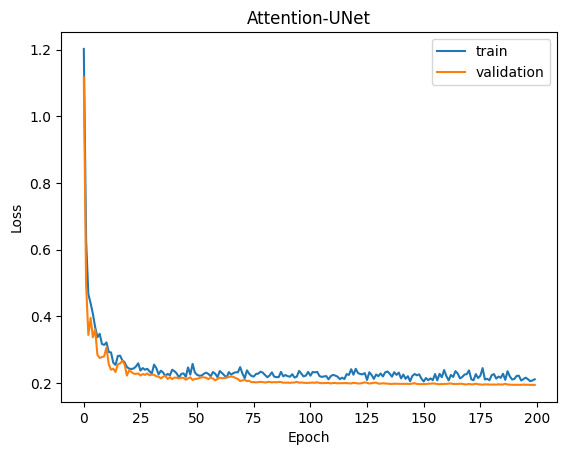

In [63]:
view_train_graphs('Attention-UNet',attentionunet_train_history, attentionunet_val_history)

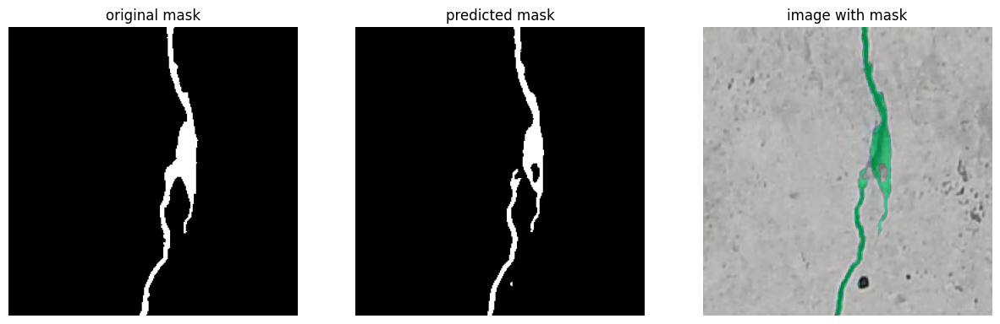

In [64]:
view_crack_segmentation(attentionunet_model, 21)

In [54]:
model = DeepLabV3().to(device)
early_stopping = EarlyStopping()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)  
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2, min_lr=1e-6)
deeplabv3_model, deeplabv3_train_history, deeplabv3_val_history = train_model(model, optimizer, early_stopping, scheduler, n_epochs=200, model_name='deeplabv3')

Epoch: 0. Train.      Loss: 1.2056 | Dice: 0.0689 | IoU: 0.0000 | Accuracy: 0.932111 | Precision: 0.191551 | Recall: 0.607638: 100%|██████████| 120/120 [00:20<00:00,  5.84it/s]
Epoch: 0. Validation. Loss: 0.9845 | Dice: 0.1518 | IoU: 0.0012 | Accuracy: 0.968361 | Precision: 0.259835 | Recall: 0.916945: 100%|██████████| 40/40 [00:01<00:00, 22.17it/s]


Validation loss decreased. Model saved!


Epoch: 1. Train.      Loss: 0.5816 | Dice: 0.4765 | IoU: 0.5995 | Accuracy: 0.987043 | Precision: 0.459383 | Recall: 0.658998: 100%|██████████| 120/120 [00:19<00:00,  6.09it/s]
Epoch: 1. Validation. Loss: 0.4655 | Dice: 0.5698 | IoU: 0.6994 | Accuracy: 0.989460 | Precision: 0.530905 | Recall: 0.693795: 100%|██████████| 40/40 [00:01<00:00, 22.34it/s]


Validation loss decreased. Model saved!


Epoch: 2. Train.      Loss: 0.5122 | Dice: 0.5362 | IoU: 0.6698 | Accuracy: 0.989308 | Precision: 0.502229 | Recall: 0.687479: 100%|██████████| 120/120 [00:19<00:00,  6.16it/s]
Epoch: 2. Validation. Loss: 0.4464 | Dice: 0.5956 | IoU: 0.7055 | Accuracy: 0.988056 | Precision: 0.480099 | Recall: 0.876056: 100%|██████████| 40/40 [00:01<00:00, 22.07it/s]


Validation loss decreased. Model saved!


... (86 outputs left out)

Epoch: 196. Train.      Loss: 0.2816 | Dice: 0.7443 | IoU: 0.7534 | Accuracy: 0.994285 | Precision: 0.668940 | Recall: 0.839998: 100%|██████████| 120/120 [00:19<00:00,  6.25it/s]
Epoch: 196. Validation. Loss: 0.2883 | Dice: 0.7444 | IoU: 0.7862 | Accuracy: 0.993450 | Precision: 0.649956 | Recall: 0.854705: 100%|██████████| 40/40 [00:01<00:00, 22.60it/s]
Epoch: 197. Train.      Loss: 0.2947 | Dice: 0.7309 | IoU: 0.7466 | Accuracy: 0.994364 | Precision: 0.657852 | Recall: 0.845175: 100%|██████████| 120/120 [00:19<00:00,  6.15it/s]
Epoch: 197. Validation. Loss: 0.2881 | Dice: 0.7445 | IoU: 0.7865 | Accuracy: 0.993471 | Precision: 0.651276 | Recall: 0.852819: 100%|██████████| 40/40 [00:01<00:00, 22.48it/s]


Validation loss decreased. Model saved!


Epoch: 198. Train.      Loss: 0.2965 | Dice: 0.7292 | IoU: 0.7536 | Accuracy: 0.994343 | Precision: 0.668118 | Recall: 0.846259: 100%|██████████| 120/120 [00:18<00:00,  6.34it/s]
Epoch: 198. Validation. Loss: 0.2886 | Dice: 0.7444 | IoU: 0.7861 | Accuracy: 0.993410 | Precision: 0.647748 | Recall: 0.857407: 100%|██████████| 40/40 [00:01<00:00, 22.30it/s]
Epoch: 199. Train.      Loss: 0.2835 | Dice: 0.7429 | IoU: 0.7682 | Accuracy: 0.994261 | Precision: 0.682709 | Recall: 0.856745: 100%|██████████| 120/120 [00:19<00:00,  6.22it/s]
Epoch: 199. Validation. Loss: 0.2889 | Dice: 0.7442 | IoU: 0.7861 | Accuracy: 0.993427 | Precision: 0.649239 | Recall: 0.855148: 100%|██████████| 40/40 [00:01<00:00, 22.52it/s]


Best Dice: 0.7445


In [55]:
test(deeplabv3_model)

Loss: 0.2817 | Dice: 0.7471 | IoU: 0.7940 | Accuracy: 0.993814 | Precision: 0.653354 | Recall: 0.847624: 100%|██████████| 40/40 [00:01<00:00, 20.47it/s]


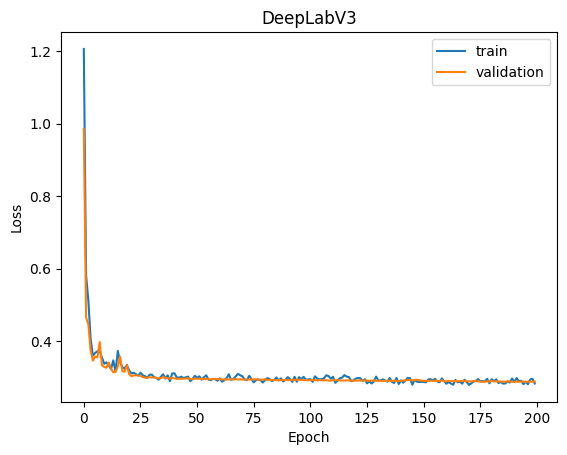

In [56]:
view_train_graphs('DeepLabV3',deeplabv3_train_history, deeplabv3_val_history)

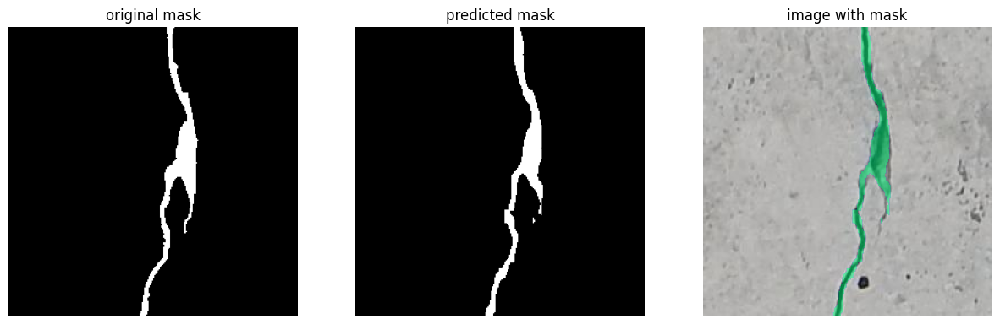

In [57]:
view_crack_segmentation(deeplabv3_model, 21)

In [58]:
model = DeepLabV3Plus().to(device)
early_stopping = EarlyStopping()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)  
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2, min_lr=1e-6)
deeplabv3plus_model, deeplabv3plus_train_history, deeplabv3plus_val_history = train_model(model, optimizer, early_stopping, scheduler, n_epochs=200, model_name='deeplabv3plus')

Epoch: 0. Train.      Loss: 1.3684 | Dice: 0.0425 | IoU: 0.0000 | Accuracy: 0.861550 | Precision: 0.209304 | Recall: 0.605187: 100%|██████████| 120/120 [00:15<00:00,  7.59it/s]
Epoch: 0. Validation. Loss: 1.0965 | Dice: 0.0771 | IoU: 0.0000 | Accuracy: 0.987257 | Precision: 0.486672 | Recall: 0.585970: 100%|██████████| 40/40 [00:01<00:00, 28.04it/s]
Epoch: 1. Train.      Loss: 0.6968 | Dice: 0.3558 | IoU: 0.4318 | Accuracy: 0.986933 | Precision: 0.443789 | Recall: 0.454378: 100%|██████████| 120/120 [00:14<00:00,  8.13it/s]
Epoch: 1. Validation. Loss: 0.4345 | Dice: 0.5948 | IoU: 0.6979 | Accuracy: 0.991305 | Precision: 0.603108 | Recall: 0.659151: 100%|██████████| 40/40 [00:01<00:00, 27.93it/s]


Validation loss decreased. Model saved!


Epoch: 2. Train.      Loss: 0.4238 | Dice: 0.6035 | IoU: 0.6679 | Accuracy: 0.992252 | Precision: 0.598091 | Recall: 0.698964: 100%|██████████| 120/120 [00:14<00:00,  8.25it/s]
Epoch: 2. Validation. Loss: 0.3305 | Dice: 0.6974 | IoU: 0.7427 | Accuracy: 0.992000 | Precision: 0.599464 | Recall: 0.829732: 100%|██████████| 40/40 [00:01<00:00, 27.95it/s]


Validation loss decreased. Model saved!


Epoch: 3. Train.      Loss: 0.3527 | Dice: 0.6732 | IoU: 0.7187 | Accuracy: 0.993187 | Precision: 0.651423 | Recall: 0.758133: 100%|██████████| 120/120 [00:14<00:00,  8.14it/s]
Epoch: 3. Validation. Loss: 0.3112 | Dice: 0.7150 | IoU: 0.7569 | Accuracy: 0.992506 | Precision: 0.611898 | Recall: 0.841744: 100%|██████████| 40/40 [00:01<00:00, 28.70it/s]


Validation loss decreased. Model saved!


... (108 outputs left out)

Epoch: 183. Train.      Loss: 0.2395 | Dice: 0.7797 | IoU: 0.7979 | Accuracy: 0.995303 | Precision: 0.734260 | Recall: 0.827177: 100%|██████████| 120/120 [00:14<00:00,  8.31it/s]
Epoch: 183. Validation. Loss: 0.2183 | Dice: 0.8002 | IoU: 0.8196 | Accuracy: 0.995176 | Precision: 0.729872 | Recall: 0.860481: 100%|██████████| 40/40 [00:01<00:00, 28.21it/s]
Epoch: 184. Train.      Loss: 0.2311 | Dice: 0.7875 | IoU: 0.7871 | Accuracy: 0.995487 | Precision: 0.731646 | Recall: 0.825981: 100%|██████████| 120/120 [00:15<00:00,  7.98it/s]
Epoch: 184. Validation. Loss: 0.2172 | Dice: 0.8008 | IoU: 0.8200 | Accuracy: 0.995235 | Precision: 0.735054 | Recall: 0.855945: 100%|██████████| 40/40 [00:01<00:00, 27.97it/s]


Validation loss decreased. Model saved!


Epoch: 185. Train.      Loss: 0.2354 | Dice: 0.7824 | IoU: 0.7942 | Accuracy: 0.995510 | Precision: 0.744707 | Recall: 0.837291: 100%|██████████| 120/120 [00:14<00:00,  8.02it/s]
Epoch: 185. Validation. Loss: 0.2175 | Dice: 0.8007 | IoU: 0.8195 | Accuracy: 0.995204 | Precision: 0.731497 | Recall: 0.860570: 100%|██████████| 40/40 [00:01<00:00, 28.22it/s]
Epoch: 186. Train.      Loss: 0.2349 | Dice: 0.7845 | IoU: 0.7864 | Accuracy: 0.995256 | Precision: 0.742988 | Recall: 0.845376: 100%|██████████| 120/120 [00:14<00:00,  8.14it/s]
Epoch: 186. Validation. Loss: 0.2178 | Dice: 0.8003 | IoU: 0.8197 | Accuracy: 0.995212 | Precision: 0.734266 | Recall: 0.855594: 100%|██████████| 40/40 [00:01<00:00, 28.06it/s]
Epoch: 187. Train.      Loss: 0.2343 | Dice: 0.7842 | IoU: 0.7910 | Accuracy: 0.995524 | Precision: 0.745751 | Recall: 0.840877: 100%|██████████| 120/120 [00:15<00:00,  7.86it/s]
Epoch: 187. Validation. Loss: 0.2186 | Dice: 0.7999 | IoU: 0.8195 | Accuracy: 0.995162 | Precision: 0.730268 

Best Dice: 0.8008


In [59]:
test(deeplabv3plus_model)

Loss: 0.2180 | Dice: 0.7995 | IoU: 0.8275 | Accuracy: 0.995476 | Precision: 0.748106 | Recall: 0.835386: 100%|██████████| 40/40 [00:01<00:00, 28.16it/s]


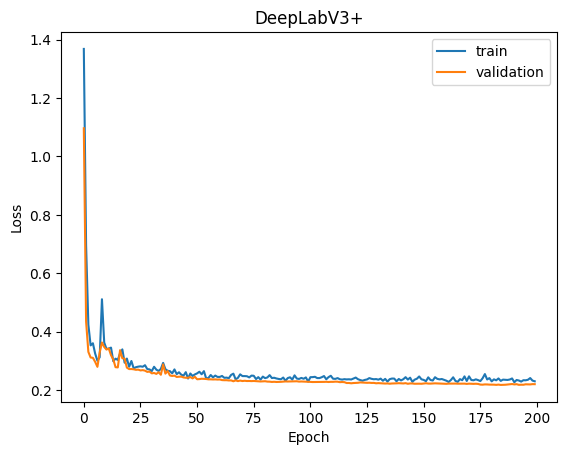

In [60]:
view_train_graphs('DeepLabV3+',deeplabv3plus_train_history, deeplabv3plus_val_history)

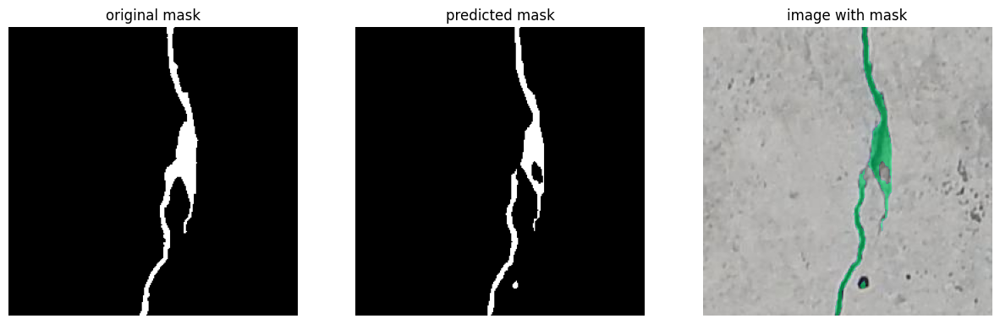

In [61]:
view_crack_segmentation(deeplabv3plus_model, 21)

In [46]:
model = Segformer().to(device)
early_stopping = EarlyStopping()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)  
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2, min_lr=1e-6)
segformer_model, segformer_train_history, segformer_val_history = train_model(model, optimizer, early_stopping, scheduler, n_epochs=200, model_name='segformer')

Epoch: 0. Train.      Loss: 1.1434 | Dice: 0.1005 | IoU: 0.0002 | Accuracy: 0.922583 | Precision: 0.280108 | Recall: 0.708494: 100%|██████████| 120/120 [00:22<00:00,  5.36it/s]
Epoch: 0. Validation. Loss: 0.7901 | Dice: 0.2660 | IoU: 0.0026 | Accuracy: 0.988434 | Precision: 0.493753 | Recall: 0.859044: 100%|██████████| 40/40 [00:01<00:00, 20.29it/s]


Validation loss decreased. Model saved!


Epoch: 1. Train.      Loss: 0.4268 | Dice: 0.6000 | IoU: 0.6394 | Accuracy: 0.991636 | Precision: 0.622077 | Recall: 0.721108: 100%|██████████| 120/120 [00:20<00:00,  5.98it/s]
Epoch: 1. Validation. Loss: 0.3031 | Dice: 0.7225 | IoU: 0.7609 | Accuracy: 0.992455 | Precision: 0.604531 | Recall: 0.876976: 100%|██████████| 40/40 [00:01<00:00, 20.09it/s]


Validation loss decreased. Model saved!


Epoch: 2. Train.      Loss: 0.3267 | Dice: 0.6980 | IoU: 0.7218 | Accuracy: 0.993634 | Precision: 0.677041 | Recall: 0.777434: 100%|██████████| 120/120 [00:20<00:00,  5.95it/s]
Epoch: 2. Validation. Loss: 0.3198 | Dice: 0.7097 | IoU: 0.7686 | Accuracy: 0.993284 | Precision: 0.738691 | Recall: 0.677411: 100%|██████████| 40/40 [00:02<00:00, 19.96it/s]
Epoch: 3. Train.      Loss: 0.3148 | Dice: 0.7132 | IoU: 0.7405 | Accuracy: 0.993522 | Precision: 0.666789 | Recall: 0.779861: 100%|██████████| 120/120 [00:19<00:00,  6.07it/s]
Epoch: 3. Validation. Loss: 0.2807 | Dice: 0.7457 | IoU: 0.7796 | Accuracy: 0.993412 | Precision: 0.650639 | Recall: 0.839104: 100%|██████████| 40/40 [00:01<00:00, 20.53it/s]


Validation loss decreased. Model saved!


... (132 outputs left out)

Epoch: 197. Train.      Loss: 0.1994 | Dice: 0.8174 | IoU: 0.8147 | Accuracy: 0.996104 | Precision: 0.769386 | Recall: 0.857728: 100%|██████████| 120/120 [00:20<00:00,  5.96it/s]
Epoch: 197. Validation. Loss: 0.1848 | Dice: 0.8322 | IoU: 0.8451 | Accuracy: 0.995987 | Precision: 0.771911 | Recall: 0.868077: 100%|██████████| 40/40 [00:01<00:00, 20.50it/s]


Validation loss decreased. Model saved!


Epoch: 198. Train.      Loss: 0.1991 | Dice: 0.8168 | IoU: 0.8155 | Accuracy: 0.996278 | Precision: 0.775487 | Recall: 0.868883: 100%|██████████| 120/120 [00:20<00:00,  5.91it/s]
Epoch: 198. Validation. Loss: 0.1851 | Dice: 0.8321 | IoU: 0.8450 | Accuracy: 0.995975 | Precision: 0.771024 | Recall: 0.869056: 100%|██████████| 40/40 [00:01<00:00, 20.19it/s]
Epoch: 199. Train.      Loss: 0.1979 | Dice: 0.8183 | IoU: 0.8158 | Accuracy: 0.996211 | Precision: 0.780038 | Recall: 0.864775: 100%|██████████| 120/120 [00:20<00:00,  5.98it/s]
Epoch: 199. Validation. Loss: 0.1852 | Dice: 0.8320 | IoU: 0.8449 | Accuracy: 0.995965 | Precision: 0.769573 | Recall: 0.870756: 100%|██████████| 40/40 [00:02<00:00, 19.84it/s]


Best Dice: 0.8322


In [47]:
test(segformer_model)

Loss: 0.1873 | Dice: 0.8293 | IoU: 0.8494 | Accuracy: 0.996174 | Precision: 0.773265 | Recall: 0.861538: 100%|██████████| 40/40 [00:02<00:00, 18.23it/s]


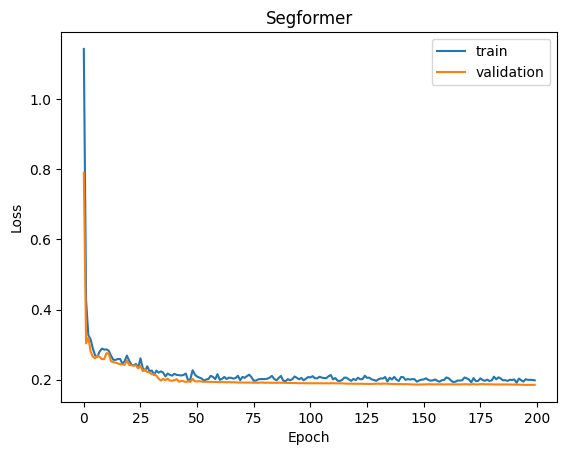

In [50]:
view_train_graphs('Segformer',segformer_train_history, segformer_val_history)

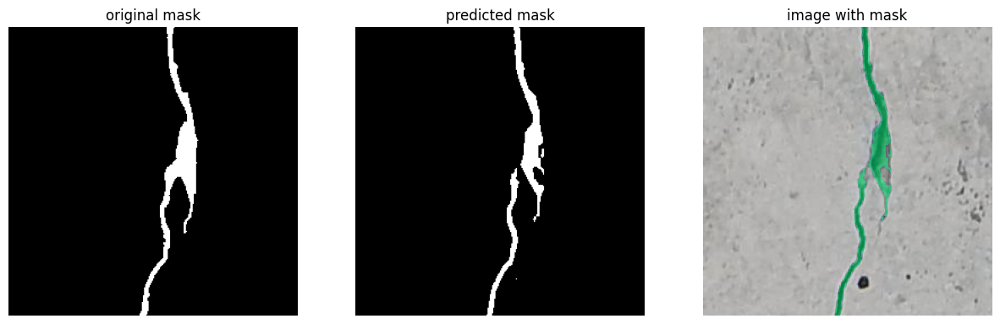

In [51]:
view_crack_segmentation(segformer_model, 21)

### Результаты обучения

Модель|	Loss|	Dice|	mIoU|	Accuracy|	Precision|	Recall
|-----|------|-------|-------|-----------|------------|--------|
UNet|	0.1724| 	0.8420| 	0.8582| 	0.996560| 	0.817721| 	0.833831
UNet++|	0.1655| 	0.8485| 	0.8642| 	0.996699| 	0.821475| 	0.839752
UNet++(DenseNet)|	0.1652| 	0.8488| 	0.8664| 	0.996666| 	0.818714| 	0.843958
Linknet|	0.1686| 	0.8455| 	0.8628| 	0.996597| 	0.818025| 	0.836152
Attention-UNet|	0.2122|  	0.8047| 	0.8507| 	0.996178| 	0.796879| 	0.827655
DeepLabV3|	0.2817| 	0.7471| 	0.7940| 	0.993814| 	0.653354| 	0.847624
DeepLabV3+|	0.2180| 	0.7995| 	0.8275| 	0.995476| 	0.748106| 	0.835386
Segformer|	0.1873| 	0.8293| 	0.8494| 	0.996174| 	0.773265| 	0.861538

### Сравнение работы моделей

In [42]:
def view_models_compare(model_dic, image_indexes):
    num_rows = len(image_indexes)
    num_cols = 2 + len(model_dic)
    fig, axes = plt.subplots(nrows=num_rows, ncols=num_cols, figsize=(25, 25*num_rows/num_cols))
    for i, idx in enumerate(image_indexes):
        img_path = df[df['cracked']==1]['image'].iloc[idx]
        img = image = cv.imread(img_path, cv.IMREAD_COLOR_RGB)

        mask_path = df[df['cracked']==1]['mask'].iloc[idx]
        mask = cv.imread(mask_path, cv.IMREAD_COLOR_RGB)

        _, true_mask = cv.threshold(mask, 1, 255, cv.THRESH_BINARY)
        
        #if i == 0:
        axes[i,0].set_title('image ' + str(idx))
        axes[i,1].set_title('original mask')

        axes[i,0].axis('off')
        axes[i,0].imshow(img)
        axes[i,1].axis('off')
        axes[i,1].imshow(true_mask)

        augmented = val_transform(image=image)
        image = augmented['image'].float()/255
        image = image.to(device)
        image = image.unsqueeze(0)

        for delta, (model_name, model) in enumerate(model_dic.items()):
                output = model(image)
                output = output.squeeze()
                probs = torch.sigmoid(output)
                probs = probs.cpu().detach().numpy()
                mask_pred = np.where(probs > 0.5, 255, 0)

                #if i==0:
                axes[i,2+delta].set_title(model_name)
                
                axes[i,2+delta].axis('off')
                axes[i,2+delta].imshow(mask_pred, cmap='gray')

    return

### Загрузка моделей

In [43]:
unet = UNet().to('cuda')
unet.load_state_dict(torch.load('unet_resnet34.pt', weights_only=False))
unet.eval()
unetpp = UNetPlusPlus().to('cuda')
unetpp.load_state_dict(torch.load('unetpp_resnet34.pt', weights_only=False))
unetpp.eval()
unetppdn = UNetPlusPlusDN().to('cuda')
unetppdn.load_state_dict(torch.load('unetpp_densenet161.pt', weights_only=False))
unetppdn.eval()
attention_unet = AttentionUNet().to('cuda')
attention_unet.load_state_dict(torch.load('attention_unet.pt', weights_only=False))
attention_unet.eval()
linknet = Linknet().to('cuda')
linknet.load_state_dict(torch.load('linknet.pt', weights_only=False))
linknet.eval()
deeplabv3 = DeepLabV3().to('cuda')
deeplabv3.load_state_dict(torch.load('deeplabv3.pt', weights_only=False))
deeplabv3.eval()
deeplabv3plus = DeepLabV3Plus().to('cuda')
deeplabv3plus.load_state_dict(torch.load('deeplabv3plus.pt', weights_only=False))
deeplabv3plus.eval()
segformer = Segformer().to('cuda')
segformer.load_state_dict(torch.load('segformer.pt', weights_only=False))
segformer.eval()


Segformer(
  (base): Segformer(
    (encoder): DenseNetEncoder(
      (features): Sequential(
        (conv0): Conv2d(3, 96, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
        (norm0): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu0): ReLU(inplace=True)
        (pool0): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
        (denseblock1): _DenseBlock(
          (denselayer1): _DenseLayer(
            (norm1): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (relu1): ReLU(inplace=True)
            (conv1): Conv2d(96, 192, kernel_size=(1, 1), stride=(1, 1), bias=False)
            (norm2): BatchNorm2d(192, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (relu2): ReLU(inplace=True)
            (conv2): Conv2d(192, 48, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          )
          (denselayer2): _DenseLay




In [44]:
model_dic = {'UNet':unet,
             'UNet++':unetpp,
             'UNet++(DenseNet)':unetppdn,
             'Attention-UNet':attention_unet,
             'Linknet':linknet,
             'DeepLabV3':deeplabv3,
             'DeepLabV3+':deeplabv3plus,
             'Segformer':segformer,
             }
image_indexes = range(100)
view_models_compare(model_dic, image_indexes)

## Выводы
1. Модели на базе архитектуры U-Net имеют лучшую оценку после обучения.  

2. Применение энкодера DenseNet делает сегментацию более точной (точнее выделяются тонкие трещины). 

3. Масками в датасете выделены не все трещины, точная сегментация трещин будет иметь меньший коэффициент Dice, чем сегментация совпадающая с маской. Поэтому не всякая модель имеющая лучшую оценку будет сегментировать точнее модели с худшей оценкой.

